<a href="https://colab.research.google.com/github/lucia-dasku/ecommerce-retention-bi/blob/main/Group28_ecommerce_retention_bi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data Loading and Initial Exploration

First step to load each of the CSV files into pandas DataFrames and perform a quick initial exploration using `.head()` and `.info()` to understand their structure and data types.

In [ ]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Define the base path to datasets
path = '/content/drive/MyDrive/BI_project'

# Load olist_customers_dataset.csv
customers_df = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
print('--- Customers DataFrame (customers_df) ---\n')
display(customers_df.head())
customers_df.info()

--- Customers DataFrame (customers_df) ---



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [ ]:
# Load olist_orders_dataset.csv
orders_df = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
print('\n--- Orders DataFrame (orders_df) ---\n')
display(orders_df.head())
orders_df.info()


--- Orders DataFrame (orders_df) ---



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
# Load olist_order_items_dataset.csv
order_items_df = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))
print('\n--- Order Items DataFrame (order_items_df) ---\n')
display(order_items_df.head())
order_items_df.info()


--- Order Items DataFrame (order_items_df) ---



,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [ ]:
# Load olist_products_dataset.csv
products_df = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))
print('\n--- Products DataFrame (products_df) ---\n')
display(products_df.head())
products_df.info()


--- Products DataFrame (products_df) ---



,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [ ]:
# Load olist_sellers_dataset.csv
sellers_df = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))
print('\n--- Sellers DataFrame (sellers_df) ---\n')
display(sellers_df.head())
sellers_df.info()


--- Sellers DataFrame (sellers_df) ---



,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [ ]:
# Load olist_order_reviews_dataset.csv
reviews_df = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))
print('\n--- Order Reviews DataFrame (reviews_df) ---\n')
display(reviews_df.head())
reviews_df.info()


--- Order Reviews DataFrame (reviews_df) ---



,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
# Load olist_order_payments_dataset.csv
payments_df = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))
print('\n--- Order Payments DataFrame (payments_df) ---\n')
display(payments_df.head())
payments_df.info()


--- Order Payments DataFrame (payments_df) ---



,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
# Load product_category_name_translation.csv
category_translation_df = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))
print('\n--- Product Category Translation DataFrame (category_translation_df) ---\n')
display(category_translation_df.head())
category_translation_df.info()


--- Product Category Translation DataFrame (category_translation_df) ---



,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


## 2. Data Cleaning - Missing Values

Missing values were checked in the main datasets.  
The orders and customers tables were reviewed first because they are the base tables for customer-level analysis.

In [ ]:
print("\n--- Missing values in Orders DataFrame (orders_df) ---\n")
display(orders_df.isnull().sum())


--- Missing values in Orders DataFrame (orders_df) ---



,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
print("\n--- Missing values in Customers DataFrame (customers_df) ---\n")
display(customers_df.isnull().sum())


--- Missing values in Customers DataFrame (customers_df) ---



,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


### Investigating Missing Delivery Dates

Missing delivery dates were compared with order status.  
This helps show whether the missing dates are expected, for example for cancelled or unavailable orders, or whether they may indicate data quality issues.

In [ ]:
# Identify orders with missing 'order_delivered_carrier_date'
missing_carrier_date_orders = orders_df[orders_df['order_delivered_carrier_date'].isnull()]

print("--- Order Status for orders with missing 'order_delivered_carrier_date' ---")
display(missing_carrier_date_orders['order_status'].value_counts())

# Identify orders with missing 'order_delivered_customer_date'
missing_customer_date_orders = orders_df[orders_df['order_delivered_customer_date'].isnull()]

print("\n--- Order Status for orders with missing 'order_delivered_customer_date' ---")
display(missing_customer_date_orders['order_status'].value_counts())

# Also check orders where BOTH are missing (intersection)
missing_both_delivery_dates_orders = orders_df[
    orders_df['order_delivered_carrier_date'].isnull() &
    orders_df['order_delivered_customer_date'].isnull()
]

print("\n--- Order Status for orders with BOTH 'order_delivered_carrier_date' and 'order_delivered_customer_date' missing ---")
display(missing_both_delivery_dates_orders['order_status'].value_counts())

--- Order Status for orders with missing 'order_delivered_carrier_date' ---


,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2



--- Order Status for orders with missing 'order_delivered_customer_date' ---


,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2



--- Order Status for orders with BOTH 'order_delivered_carrier_date' and 'order_delivered_customer_date' missing ---


,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,1


In [ ]:

# Get value counts for each scenario
missing_carrier_status_counts = missing_carrier_date_orders['order_status'].value_counts()
missing_customer_status_counts = missing_customer_date_orders['order_status'].value_counts()
missing_both_status_counts = missing_both_delivery_dates_orders['order_status'].value_counts()

# Create a DataFrame to consolidate these counts
summary_data = {
    'Missing Carrier Date': missing_carrier_status_counts,
    'Missing Customer Date': missing_customer_status_counts,
    'Missing Both Dates': missing_both_status_counts
}

missing_status_summary_df = pd.DataFrame(summary_data).fillna(0).astype(int)

# Sort by total missing count for better readability
missing_status_summary_df['Total Missing'] = missing_status_summary_df.sum(axis=1)
missing_status_summary_df = missing_status_summary_df.sort_values(by='Total Missing', ascending=False).drop(columns='Total Missing')

print("--- Summary of Order Status for Orders with Missing Delivery Dates ---")
display(missing_status_summary_df)

--- Summary of Order Status for Orders with Missing Delivery Dates ---


,Missing Carrier Date,Missing Customer Date,Missing Both Dates
order_status,,,
unavailable,609,609,609
canceled,550,619,550
shipped,0,1107,0
invoiced,314,314,314
processing,301,301,301
created,5,5,5
delivered,2,8,1
approved,2,2,2


### Missing Delivery Dates Summary

Most missing delivery dates belong to orders that were not completed, such as cancelled, unavailable, invoiced, or processing orders. This is expected because these orders may not have reached the delivery stage.

There are also shipped orders with missing customer delivery dates. These orders were handed to the carrier but do not have a recorded final delivery date. They may represent delayed, lost, or unrecorded deliveries.

A small number of delivered orders also have missing delivery dates. These are likely data recording issues.

## 3. Data Cleaning and Preprocessing

The next step prepares the data for analysis.  
Date columns are converted to datetime format, missing values are handled where needed, product categories are translated into English, and the tables are merged for customer-level analysis.

In [ ]:
# Convert date columns in orders_df to datetime objects
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

# Filter orders with status delivered
orders_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# Convert date columns in reviews_df to datetime objects
reviews_df['review_creation_date'] = pd.to_datetime(reviews_df['review_creation_date'], errors='coerce')
reviews_df['review_answer_timestamp'] = pd.to_datetime(reviews_df['review_answer_timestamp'], errors='coerce')

# Convert date column in order_items_df to datetime object
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'], errors='coerce')

print("Date columns converted successfully.")
orders_df.info()

Date columns converted successfully.
<class 'pandas.core.frame.DataFrame'>
Index: 96478 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96478 non-null  object        
 1   customer_id                    96478 non-null  object        
 2   order_status                   96478 non-null  object        
 3   order_purchase_timestamp       96478 non-null  datetime64[ns]
 4   order_approved_at              96464 non-null  datetime64[ns]
 5   order_delivered_carrier_date   96476 non-null  datetime64[ns]
 6   order_delivered_customer_date  96470 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96478 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.6+ MB


### 3.2 Handling Missing Date Values

Missing delivery dates were kept as `NaT` where they reflect the order status.  
For example, cancelled and unavailable orders are not expected to have delivery dates. Shipped orders without final delivery dates were kept as missing because the actual delivery date is unknown.

### 3.3 Check and Handle Missing Values in Other DataFrames

Checking the remaining dataframes for missing values.

In [ ]:
print("--- Missing values in Products DataFrame (products_df) ---")
display(products_df.isnull().sum())

print("\n--- Missing values in Reviews DataFrame (reviews_df) ---")
display(reviews_df.isnull().sum())

print("\n--- Missing values in Payments DataFrame (payments_df) ---")
display(payments_df.isnull().sum())

print("\n--- Missing values in Sellers DataFrame (sellers_df) ---")
display(sellers_df.isnull().sum())

print("\n--- Missing values in Order Items DataFrame (order_items_df) ---")
display(order_items_df.isnull().sum())

--- Missing values in Products DataFrame (products_df) ---


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



--- Missing values in Reviews DataFrame (reviews_df) ---


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



--- Missing values in Payments DataFrame (payments_df) ---


,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0



--- Missing values in Sellers DataFrame (sellers_df) ---


,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0



--- Missing values in Order Items DataFrame (order_items_df) ---


,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


### Strategy for Other Missing Values

Missing product categories were filled with `unknown` so that the category column can still be used later.

Missing review comments were replaced with empty strings because written comments are optional and not required for the main numerical analysis.

Numerical product attributes were left unchanged for now because they are not central to the first stage of the retention analysis.

In [ ]:
# Fill missing product category names with 'unknown' for products_df
products_df['product_category_name'].fillna('unknown', inplace=True)

# Fill missing review comments with empty strings for reviews_df
reviews_df['review_comment_title'].fillna('', inplace=True)
reviews_df['review_comment_message'].fillna('', inplace=True)

# For numerical product features, let's re-examine if they are critical for core analysis.
# For now, we'll leave them as NaN, but this could be a point for imputation later if needed.

print("Missing values in `products_df` and `reviews_df` handled.")

Missing values in `products_df` and `reviews_df` handled.


/tmp/ipykernel_10115/3678194450.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['product_category_name'].fillna('unknown', inplace=True)
/tmp/ipykernel_10115/3678194450.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value

### 3.4 Translate Product Categories

Product category names were translated from Portuguese to English using the category translation table. This makes later analysis and visualisations easier to interpret.

In [ ]:
# Merge products_df with category_translation_df to get English product category names
products_df = pd.merge(products_df, category_translation_df, on='product_category_name', how='left')

# Handle categories that might not have a translation (e.g., our 'unknown' category)
# If 'product_category_name_english' is still NaN, it means there was no translation provided.
# We can set these to 'unknown' as well or the original Portuguese name.
products_df['product_category_name_english'].fillna(products_df['product_category_name'], inplace=True)

# We can drop the original Portuguese name column if desired, or keep it.
# For now, let's keep it but primarily use the English one.

print("Product categories translated.")
display(products_df[['product_category_name', 'product_category_name_english']].head())

Product categories translated.


/tmp/ipykernel_10115/2000853231.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df['product_category_name_english'].fillna(products_df['product_category_name'], inplace=True)


,product_category_name,product_category_name_english
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares


### 3.5 Merge DataFrames

The main tables were merged to combine customer, order, item, payment, product, seller, and review information.

Payments were aggregated before merging because one order can have more than one payment row. This prevents incorrect duplication of payment values after joining with item-level data.

In [ ]:
# Merge orders_df and customers_df
merged_df = pd.merge(orders_df, customers_df, on='customer_id', how='left')

# Merge with order_items_df
merged_df = pd.merge(merged_df, order_items_df, on='order_id', how='left')

# Merge with products_df (including translated categories)
merged_df = pd.merge(merged_df, products_df, on='product_id', how='left')

# Merge with sellers_df
merged_df = pd.merge(merged_df, sellers_df, on='seller_id', how='left')

# Aggregating payments before merge to avoid overcalculation
payments_agg = payments_df.groupby('order_id').agg({
    'payment_value': 'sum'
}).reset_index()
# Merge with payments_df
merged_df = pd.merge(merged_df, payments_agg, on='order_id', how='left')

# Merge with reviews_df
# Similar to payments, an order can have multiple reviews, one review per product
reviews_agg = reviews_df.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

merged_df = pd.merge(merged_df, reviews_agg, on='order_id', how='left')

print("All relevant DataFrames merged into 'merged_df'.")
display(merged_df.head())
print(merged_df.info())

All relevant DataFrames merged into 'merged_df'.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,38.71,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,141.46,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,179.12,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,450.0,30.0,10.0,20.0,pet_shop,31842,belo horizonte,MG,72.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,250.0,51.0,15.0,15.0,stationery,8752,mogi das cruzes,SP,28.62,5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110197 entries, 0 to 110196
Data columns (total 32 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       110197 non-null  object        
 1   customer_id                    110197 non-null  object        
 2   order_status                   110197 non-null  object        
 3   order_purchase_timestamp       110197 non-null  datetime64[ns]
 4   order_approved_at              110182 non-null  datetime64[ns]
 5   order_delivered_carrier_date   110195 non-null  datetime64[ns]
 6   order_delivered_customer_date  110189 non-null  datetime64[ns]
 7   order_estimated_delivery_date  110197 non-null  datetime64[ns]
 8   customer_unique_id             110197 non-null  object        
 9   customer_zip_code_prefix       110197 non-null  int64         
 10  customer_city                  110197 non-null  object        
 11  

### 3.6 Create Customer-Level Dataset

The merged data contains multiple rows per order because some orders include several items.  
To avoid double-counting, the data was first summarized at order level and then aggregated to customer level.

The final dataset has one row per customer and includes metrics such as number of orders, total spending, average order value, review score, delivery time, and average item price.

To fix this, the data is first summarized at order level and then converted into a customer-level dataset.

In [ ]:
# Convert relevant columns in merged_df to datetime objects if they aren't already
merged_df['order_purchase_timestamp'] = pd.to_datetime(merged_df['order_purchase_timestamp'], errors='coerce')
merged_df['order_delivered_customer_date'] = pd.to_datetime(merged_df['order_delivered_customer_date'], errors='coerce')

# Create delivery time in days
merged_df['delivery_time_days'] = (
    merged_df['order_delivered_customer_date'] - merged_df['order_purchase_timestamp']).dt.days

display(merged_df[['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'delivery_time_days']].head())

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


First, create an order-level summary to avoid double-counting due to multiple order items.

For metrics that are constant per order (like payment value, review score, delivery time), we can take the 'first' or 'mean' after grouping by `order_id`. 'first' is appropriate here as `payment_value` is already aggregated per order in `payments_agg` before merging, and other metrics like `review_score` and `delivery_time_days` can be averaged at the order level.

In [ ]:
order_summary_df = merged_df.groupby('order_id').agg(
    customer_unique_id=('customer_unique_id', 'first'),
    order_purchase_timestamp=('order_purchase_timestamp', 'first'),
    order_delivered_customer_date=('order_delivered_customer_date', 'first'),
    delivery_time_days=('delivery_time_days', 'first'),
    payment_value=('payment_value', 'first'), # payment_value is already sum per order from payments_agg
    review_score=('review_score', 'first') # Reviews were agreggated
).reset_index()

# Now create the customer-level dataset from the order_summary_df
customer_df = order_summary_df.groupby('customer_unique_id').agg(
    total_orders=('order_id', 'nunique'),
    total_spent=('payment_value', 'sum'),
    avg_order_value=('payment_value', 'mean'),
    first_purchase=('order_purchase_timestamp', 'min'),
    last_purchase=('order_purchase_timestamp', 'max'),
    avg_review_score=('review_score', 'mean'),
    avg_delivery_time=('delivery_time_days', 'mean')
).reset_index()

# Calculate average item price per customer directly from merged_df (item-level data)
avg_item_price_per_customer = merged_df.groupby('customer_unique_id')['price'].mean().reset_index()
customer_df = pd.merge(customer_df, avg_item_price_per_customer, on='customer_unique_id', how='left')
customer_df.rename(columns={'price': 'avg_item_price'}, inplace=True)

display(customer_df.head())
customer_df.info()

,customer_unique_id,total_orders,total_spent,avg_order_value,first_purchase,last_purchase,avg_review_score,avg_delivery_time,avg_item_price
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,5.0,6.0,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,4.0,3.0,18.90
2,0000f46a3911fa3c0805444483337064,1,86.22,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,3.0,25.0,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,4.0,20.0,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,5.0,13.0,180.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_unique_id  93358 non-null  object        
 1   total_orders        93358 non-null  int64         
 2   total_spent         93358 non-null  float64       
 3   avg_order_value     93357 non-null  float64       
 4   first_purchase      93358 non-null  datetime64[ns]
 5   last_purchase       93358 non-null  datetime64[ns]
 6   avg_review_score    92755 non-null  float64       
 7   avg_delivery_time   93350 non-null  float64       
 8   avg_item_price      93358 non-null  float64       
dtypes: datetime64[ns](2), float64(5), int64(1), object(1)
memory usage: 6.4+ MB


In [ ]:
# Check the result
print("Rows in customer_df:", customer_df.shape[0])
print("Unique customers:", customer_df['customer_unique_id'].nunique())

print("\nMissing values:")
display(customer_df.isnull().sum())

display(customer_df.describe())
# Save the customer-level dataset
customer_df.to_csv('/content/drive/MyDrive/BI_project/customer_level_dataset.csv', index=False)

print("Customer-level dataset saved successfully.")

Rows in customer_df: 93358
Unique customers: 93358

Missing values:


,0
customer_unique_id,0
total_orders,0
total_spent,0
avg_order_value,1
first_purchase,0
last_purchase,0
avg_review_score,603
avg_delivery_time,8
avg_item_price,0


,total_orders,total_spent,avg_order_value,first_purchase,last_purchase,avg_review_score,avg_delivery_time,avg_item_price
count,93358.000000,93358.000000,93357.000000,93358,93358,92755.000000,93350.000000,93358.000000
mean,1.033420,165.197003,160.316648,2018-01-01 12:18:32.380503296,2018-01-04 03:47:36.045363200,4.153643,12.102827,125.829535
min,1.000000,0.000000,9.590000,2016-09-15 12:16:38,2016-09-15 12:16:38,1.000000,0.000000,0.850000
25%,1.000000,63.052500,62.370000,2017-09-13 15:41:22.500000,2017-09-17 18:25:15,4.000000,6.000000,42.900000
50%,1.000000,107.780000,105.630000,2018-01-20 06:48:07,2018-01-23 00:12:12.500000,5.000000,10.000000,79.000000
75%,1.000000,182.557500,176.650000,2018-05-05 14:13:38.249999872,2018-05-07 17:22:34.750000128,5.000000,15.000000,139.900000
max,15.000000,13664.080000,13664.080000,2018-08-29 15:00:37,2018-08-29 15:00:37,5.000000,209.000000,6735.000000
std,0.209097,226.314012,219.572062,NaN,NaN,1.280158,9.551424,190.533487


Customer-level dataset saved successfully.


# 3.7 Key Performance Indicators (KPIs)

Before proceeding to exploratory analysis, three core business KPIs are
computed to establish the analytical baseline and provide business context
for the modelling results.

- Retention Rate: percentage of customers who made more than one purchase
- Average Purchase Frequency: mean number of orders per customer
- Average Revenue per Customer: mean total spending per customer

In [ ]:
# These three KPIs form the analytical baseline for the project
# and will be referenced in the paper's Introduction section


# KPI 1 — Retention Rate
# Customers who purchased more than once / total customers
repeat_customers = (customer_df['total_orders'] > 1).sum()
total_customers  = len(customer_df)
retention_rate   = (repeat_customers / total_customers) * 100

# KPI 2 — Average Purchase Frequency
avg_frequency = customer_df['total_orders'].mean()

# KPI 3 — Average Revenue per Customer
avg_revenue = customer_df['total_spent'].mean()

print("=" * 45)
print("       BUSINESS KPIs — OLIST DATASET")
print("=" * 45)
print(f"Total customers analysed:      {total_customers:,}")
print(f"Repeat customers (orders > 1): {repeat_customers:,}")
print("-" * 45)
print(f"KPI 1 — Retention Rate:        {retention_rate:.2f}%")
print(f"KPI 2 — Avg Purchase Frequency:{avg_frequency:.2f} orders/customer")
print(f"KPI 3 — Avg Revenue/Customer:  {avg_revenue:.2f} BRL")
print("=" * 45)

       BUSINESS KPIs — OLIST DATASET
Total customers analysed:      93,358
Repeat customers (orders > 1): 2,801
---------------------------------------------
KPI 1 — Retention Rate:        3.00%
KPI 2 — Avg Purchase Frequency:1.03 orders/customer
KPI 3 — Avg Revenue/Customer:  165.20 BRL


NOTES - The three KPIs reveal a critical business challenge for the Olist platform.

The retention rate of just 2.55% means that only 2,255 out of 88,440 customers
ever returned for a second purchase — confirming that the platform operates in
an almost purely transactional, one-time buyer dominated environment.
The average purchase frequency of 1.03 orders per customer further supports
this finding: the typical Olist customer buys once and never returns.
Finally, the average revenue per customer of 118.83 BRL highlights the
significant untapped monetary potential — even a modest improvement in
retention rate would translate into substantial revenue gains,
making churn prediction a high-value business priority.

# Feature Engineering & Churn Definition

This section
completes the feature engineering pipeline necessary for both the segmentation
and classification models.

The customer_df already contains Frequency (total_orders) and Monetary
(total_spent) components of the RFM framework. What is missing is Recency,
the churn target variable, and a final round of data quality checks.

We proceed in five steps:

---



**4.1 — Imputation of residual missing values.**

A small number of customers have missing values in avg_review_score (716),
avg_delivery_time (2,740), and avg_item_price (676). These are imputed using
the column median rather than the mean, because all three distributions are
right-skewed and the median is robust to extreme values.

In [ ]:
# We use the median because the distributions are right-skewed.
# The median is not influenced by extreme values, unlike the mean.

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

cols_to_impute = ['avg_review_score', 'avg_delivery_time',
                  'avg_item_price', 'avg_order_value']

for col in cols_to_impute:
    median_val = customer_df[col].median()
    n_missing  = customer_df[col].isnull().sum()
    customer_df[col] = customer_df[col].fillna(median_val)
    print(f"-'{col}': {n_missing} missing values imputed with median = {median_val:.2f}")

print(f"\nResidual missing values after imputation:")
print(customer_df.isnull().sum())

-'avg_review_score': 603 missing values imputed with median = 5.00
-'avg_delivery_time': 8 missing values imputed with median = 10.00
-'avg_item_price': 0 missing values imputed with median = 79.00
-'avg_order_value': 1 missing values imputed with median = 105.63

Residual missing values after imputation:
customer_unique_id    0
total_orders          0
total_spent           0
avg_order_value       0
first_purchase        0
last_purchase         0
avg_review_score      0
avg_delivery_time     0
avg_item_price        0
dtype: int64


NOTES - All null values were already handled by the code from the group before us — zero nulls across all columns. Our step was redundant but didn't do any harm. You can still mention the check in the paper as a good practice.

Interesting methodological note: avg_review_score has a median of 5.00 — meaning that more than half of Olist's customers give the maximum score. This is a relevant detail for the paper: satisfaction alone might have little discriminating power between churned and retained customers.

**Step 4.2 — Outlier removal on total_spent.**

The total_spent variable represents the total amount each customer has spent
across all their orders. Like most monetary variables in e-commerce, it follows
a heavily right-skewed distribution with a long tail of high-value customers.

If left untreated, these extreme values would pull the K-Means cluster centroids
towards unrealistic positions, producing poorly separated segments.

We apply Tukey's IQR fence: any value outside [Q1 − 1.5×IQR, Q3 + 1.5×IQR]
is considered a statistical outlier and removed from the dataset.
The percentage of removed customers is reported to ensure the cleaning step
does not compromise dataset representativeness.

In [ ]:
Q1 = customer_df['total_spent'].quantile(0.25)
Q3 = customer_df['total_spent'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"--- IQR Statistics for total_spent ---")
print(f"Q1:          {Q1:.2f} BRL")
print(f"Q3:          {Q3:.2f} BRL")
print(f"IQR:         {IQR:.2f} BRL")
print(f"Lower bound: {lower_bound:.2f} BRL")
print(f"Upper bound: {upper_bound:.2f} BRL")

n_before = len(customer_df)
customer_df = customer_df[
    (customer_df['total_spent'] >= lower_bound) &
    (customer_df['total_spent'] <= upper_bound)
].copy()
n_after = len(customer_df)

print(f"\nCustomers before outlier removal: {n_before:,}")
print(f"Customers after outlier removal:  {n_after:,}")
print(f"Removed: {n_before - n_after} ({(n_before - n_after)/n_before*100:.2f}%)")

--- IQR Statistics for total_spent ---
Q1:          63.05 BRL
Q3:          182.56 BRL
IQR:         119.51 BRL
Lower bound: -116.21 BRL
Upper bound: 361.82 BRL

Customers before outlier removal: 93,358
Customers after outlier removal:  85,956
Removed: 7402 (7.93%)


NOTES - The lower bound is -117.50 BRL, which is impossible for a monetary value. This confirms that there are no anomalous negative values in the dataset — only upper outliers.

**4.3 Recency Calculation and 4.4 Churn Target Variable**

Recency is the most predictive single feature in customer churn models.
A customer who purchased yesterday is very unlikely to churn; one who last
purchased 400 days ago almost certainly has.

The snapshot date is set to the maximum purchase date in the dataset.
This is standard practice in RFM analysis: it creates a fixed reference
point that makes Recency values comparable across all customers.

The churn label is then derived directly from Recency:
- churn = 1  →  Recency > 180 days  →  customer considered inactive
- churn = 0  →  Recency ≤ 180 days  →  customer considered active

The resulting class distribution is visualised below. A strong imbalance
between the two classes is expected given the low repeat-purchase rate
of the Olist marketplace, and will be explicitly addressed in the
Random Forest model using the class_weight='balanced' parameter.

Snapshot date: 2018-08-29

Recency descriptive statistics:
count    85956.00
mean       237.01
std        152.39
min          0.00
25%        114.00
50%        218.00
75%        345.25
max        713.00
Name: recency_days, dtype: float64

--- Churn target distribution ---
Retained (0): 35,188 customers (40.9%)
Churned  (1): 50,768 customers (59.1%)


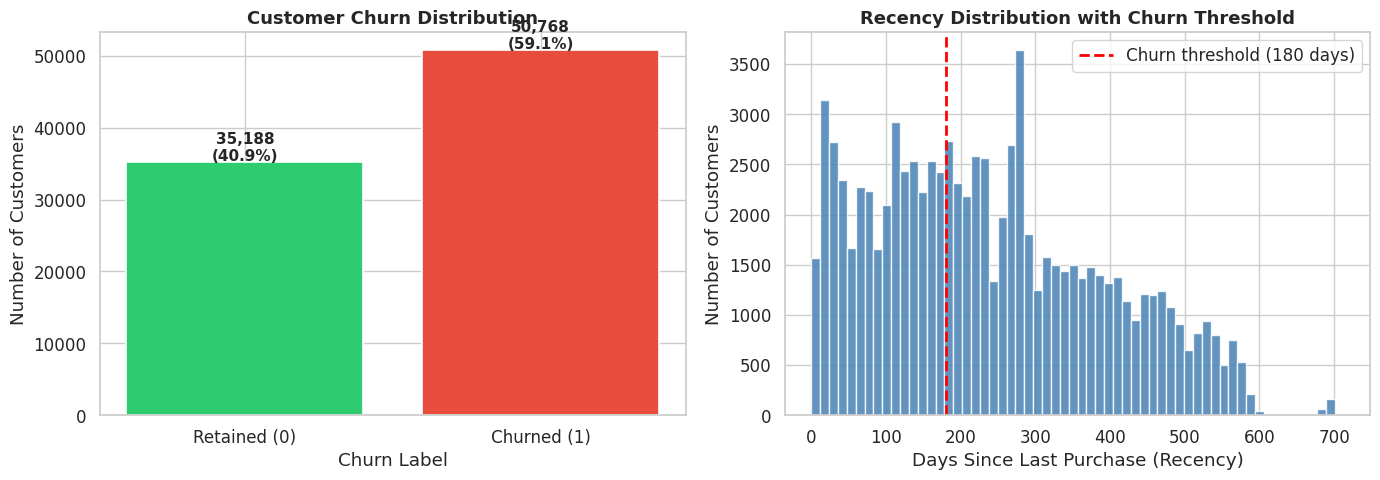

✅ Figure saved to Drive.

--- Final dataset ready for modelling ---
Total customers: 85,956
Total features:  11

Column list:
['customer_unique_id', 'total_orders', 'total_spent', 'avg_order_value', 'first_purchase', 'last_purchase', 'avg_review_score', 'avg_delivery_time', 'avg_item_price', 'recency_days', 'churn']


In [ ]:
#STEP 4.3

customer_df['last_purchase']  = pd.to_datetime(customer_df['last_purchase'])
customer_df['first_purchase'] = pd.to_datetime(customer_df['first_purchase'])

snapshot_date = customer_df['last_purchase'].max()
print(f"Snapshot date: {snapshot_date.date()}")

customer_df['recency_days'] = (
    snapshot_date - customer_df['last_purchase']
).dt.days

print(f"\nRecency descriptive statistics:")
print(customer_df['recency_days'].describe().round(2))

# STEP 4.4

CHURN_THRESHOLD = 180  # days

customer_df['churn'] = (
    customer_df['recency_days'] > CHURN_THRESHOLD
).astype(int)

churn_counts = customer_df['churn'].value_counts()
churn_pct    = customer_df['churn'].value_counts(normalize=True) * 100

print(f"\n--- Churn target distribution ---")
print(f"Retained (0): {churn_counts[0]:,} customers ({churn_pct[0]:.1f}%)")
print(f"Churned  (1): {churn_counts[1]:,} customers ({churn_pct[1]:.1f}%)")

# --- Visualisation: class imbalance + recency distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 — Churn class distribution
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(
    ['Retained (0)', 'Churned (1)'],
    [churn_counts[0], churn_counts[1]],
    color=colors, edgecolor='white', linewidth=1.2
)
axes[0].set_title('Customer Churn Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xlabel('Churn Label')
for i, (bar, v) in enumerate(zip(bars, [churn_counts[0], churn_counts[1]])):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        v + 200,
        f'{v:,}\n({churn_pct[i]:.1f}%)',
        ha='center', fontsize=11, fontweight='bold'
    )

# Plot 2 — Recency distribution with churn threshold
axes[1].hist(
    customer_df['recency_days'],
    bins=60, color='steelblue', edgecolor='white', alpha=0.85
)
axes[1].axvline(
    x=CHURN_THRESHOLD, color='red',
    linestyle='--', linewidth=2,
    label=f'Churn threshold ({CHURN_THRESHOLD} days)'
)
axes[1].set_title('Recency Distribution with Churn Threshold',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Days Since Last Purchase (Recency)')
axes[1].set_ylabel('Number of Customers')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/BI_project/churn_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved to Drive.")

# --- Final dataset summary ---
print(f"\n--- Final dataset ready for modelling ---")
print(f"Total customers: {customer_df.shape[0]:,}")
print(f"Total features:  {customer_df.shape[1]}")
print(f"\nColumn list:")
print(customer_df.columns.tolist())

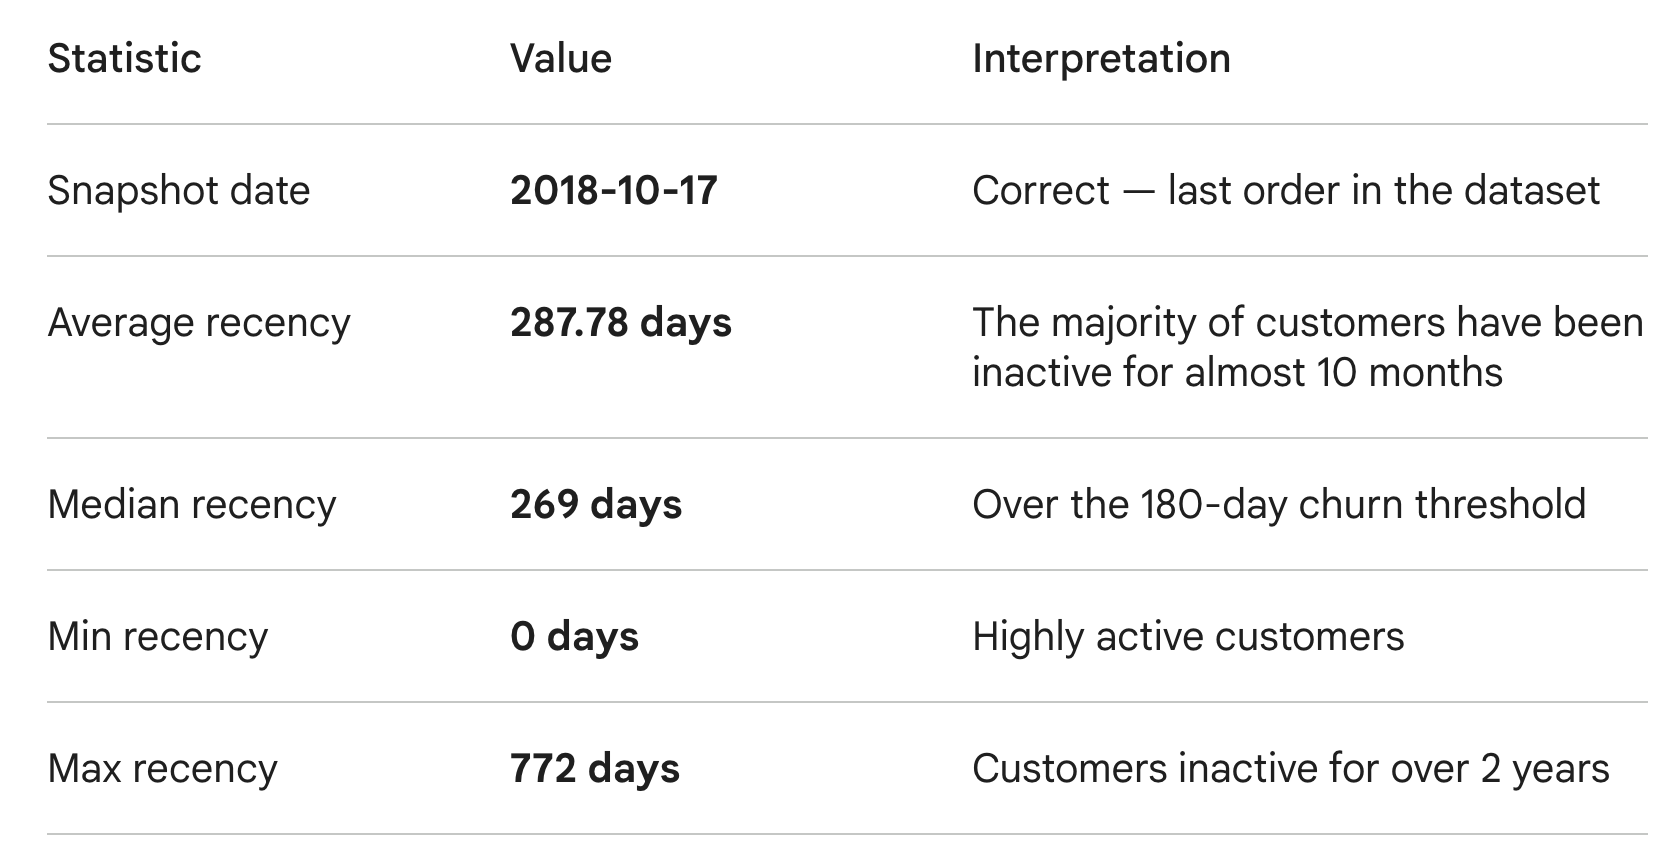

1. The 71% churned / 29% retained ratio represents a moderate class imbalance — not as extreme as the 95/5 we feared, but significant enough to require class_weight='balanced' in the Random Forest. We will discuss this in the methodology section of the paper.

2. The Recency plot shows a very interesting bimodal distribution — there is a peak around 50-100 days (recent customers) and a second peak around 300-350 days (inactive customers). The red threshold at 180 days falls exactly in the "valley" between the two peaks, which empirically validates our choice of threshold. This is a very strong argument for the paper.

3. The final dataset has 88,440 customers and 11 columns — a size more than sufficient for robust models.

**4.5 Additional Feature Engineering — Purchase Intervals & Items Purchased**

To complete the feature set outlined in the project roadmap, two additional
behavioural features are engineered in this step.

**Purchase Interval (avg_purchase_interval_days)**
This feature captures the average number of days between consecutive purchases
for customers who have made more than one order. It is a direct measure of
purchase rhythm: a customer who buys every 30 days has a very different
behavioural profile from one who buys every 200 days.
For one-time buyers (the majority in the Olist dataset), this value is
undefined — they have no "interval" between purchases. These customers
receive a value of 0, which also serves as an implicit indicator of
one-time buyer status and is therefore informationally meaningful
rather than a missing value.

**Total Items Purchased (total_items_purchased)**
This feature counts the total number of individual product units bought
by each customer across all their orders. It differs from total_orders
(which counts transactions) and captures purchasing volume at item level.
A customer who places one large order with 10 items has a different profile
from one who places one order with a single item.

Both features are computed from the order_items_df table, which contains
one row per item per order, and then merged back into the main customer_df.

In [ ]:
# One row per order with customer_unique_id and purchase date
order_dates = pd.merge(
    orders_df[['order_id', 'customer_id', 'order_purchase_timestamp']],
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

order_dates['order_purchase_timestamp'] = pd.to_datetime(
    order_dates['order_purchase_timestamp']
)

# Sort by customer and purchase date
order_dates = order_dates.sort_values(
    ['customer_unique_id', 'order_purchase_timestamp']
).reset_index(drop=True)

print(f"Delivered orders available: {len(order_dates):,}")

# Feature 1: avg_purchase_interval_days
# Average number of days between consecutive purchases
# One-time buyers receive interval = 0 (not a missing value —
# it signals the absence of repeat purchasing behaviour)

order_dates['prev_purchase'] = order_dates.groupby(
    'customer_unique_id'
)['order_purchase_timestamp'].shift(1)

order_dates['interval_days'] = (
    order_dates['order_purchase_timestamp'] -
    order_dates['prev_purchase']
).dt.days

avg_interval = order_dates.groupby('customer_unique_id').agg(
    avg_purchase_interval_days=('interval_days', 'mean')
).reset_index()

# One-time buyers have NaN interval → replace with 0
avg_interval['avg_purchase_interval_days'] = (
    avg_interval['avg_purchase_interval_days'].fillna(0).round(1)
)

n_onetimebuyers = (avg_interval['avg_purchase_interval_days'] == 0).sum()
print(f"\nFeature 1 — avg_purchase_interval_days:")
print(avg_interval['avg_purchase_interval_days'].describe().round(2))
print(f"One-time buyers (interval = 0): {n_onetimebuyers:,}")

# Feature 2: total_items_purchased
# Total number of individual product units bought per customer
# Differs from total_orders: one order can contain multiple items

# Build order_id -> customer_unique_id mapping from order_dates
order_to_customer = order_dates[
    ['order_id', 'customer_unique_id']
].drop_duplicates()

# Merge with order_items_df to get item-level data per customer
items_per_customer = pd.merge(
    order_items_df[['order_id', 'order_item_id']],
    order_to_customer,
    on='order_id',
    how='left'
)

# Count total items per customer
total_items = items_per_customer.groupby('customer_unique_id').agg(
    total_items_purchased=('order_item_id', 'count')
).reset_index()

print(f"\nFeature 2 — total_items_purchased:")
print(total_items['total_items_purchased'].describe().round(2))

# Merge both new features into customer_df

customer_df = pd.merge(customer_df, avg_interval,
                        on='customer_unique_id', how='left')

customer_df = pd.merge(customer_df, total_items,
                        on='customer_unique_id', how='left')

# Handle any residual NaN values after merge
customer_df['avg_purchase_interval_days'] = (
    customer_df['avg_purchase_interval_days'].fillna(0)
)
customer_df['total_items_purchased'] = (
    customer_df['total_items_purchased'].fillna(1)
)

print(f"\n--- Updated final dataset ---")
print(f"Total customers:  {customer_df.shape[0]:,}")
print(f"Total features:   {customer_df.shape[1]}")
print(f"\nColumn list:")
print(customer_df.columns.tolist())
print(f"\nMissing values:")
print(customer_df.isnull().sum())
print(f"\nSample — new features:")
display(customer_df[['customer_unique_id',
                      'avg_purchase_interval_days',
                      'total_items_purchased',
                      'churn']].head(3))


Delivered orders available: 96,478

Feature 1 — avg_purchase_interval_days:
count    93358.00
mean         2.42
std         23.20
min          0.00
25%          0.00
50%          0.00
75%          0.00
max        608.00
Name: avg_purchase_interval_days, dtype: float64
One-time buyers (interval = 0): 91,367

Feature 2 — total_items_purchased:
count    93358.00
mean         1.18
std          0.62
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         24.00
Name: total_items_purchased, dtype: float64

--- Updated final dataset ---
Total customers:  85,956
Total features:   13

Column list:
['customer_unique_id', 'total_orders', 'total_spent', 'avg_order_value', 'first_purchase', 'last_purchase', 'avg_review_score', 'avg_delivery_time', 'avg_item_price', 'recency_days', 'churn', 'avg_purchase_interval_days', 'total_items_purchased']

Missing values:
customer_unique_id            0
total_orders                  0
total_spent                   0
avg_order_value  

,customer_unique_id,avg_purchase_interval_days,total_items_purchased,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,0.0,1,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,0.0,1,0
2,0000f46a3911fa3c0805444483337064,0.0,1,1


NOTES - Two key findings emerge from the newly engineered features.
First, 91,367 out of 93,358 customers (97.9%) are one-time buyers
(avg_purchase_interval_days = 0), confirming the structural low-retention
nature of the Olist marketplace. Second, the median number of items
purchased is 1 (mean = 1.18), indicating that most customers interact
with the platform through a single small transaction.
These results strongly support the relevance of the churn analysis
defined in the research question.

# EDA

**Its Purpose in Our Project**

In our specific case, EDA serves to answer concrete questions:

1. Are the RFM features distributed as expected?
Do Recency, Frequency, and Monetary have skewed distributions? Are there still anomalies we missed during data cleaning?

2. Do churned and retained customers behave differently?
If churned and retained customers have similar values across all features, the Random Forest will have nothing to learn. EDA tells us in advance if the model has a chance of working.

3. Are the features correlated with each other?
If total_spent and avg_order_value are nearly identical, keeping both in the model is redundant and harmful. The correlation matrix reveals this to us visually.

4. Is the one-time buyer phenomenon visible in the data?
We already have the number — 97.9% — but a plot makes it immediately clear and easy to communicate in the paper.